# The Central Limit Theorem, and how the bootstrap puts it to work


###Prof. Victor S. Batista
**CHEM 584: Introduction to Machine Learning and Quantum Computing**



*An annotated, pedagogical notebook. Everything is run: every number and figure below is stored output, and the text that follows each output quotes it.*

**The question.** You measure something once (or run one simulation) and get a number. How much would that number change if you could repeat the experiment? That spread, the **standard error**, is what an error bar means. The **Central Limit Theorem** (CLT) says how the spread of an average behaves. The **bootstrap** is the practical way to *measure* that spread from the single sample you actually have.

**What you will do.**

| Part | Question | Section |
|---|---|---|
| 1 | What does one experiment (100 rolls of a fair die) look like? | 2 |
| 2 | How is the *mean* of 100 rolls distributed, and how does its spread shrink with $N$? | 3, 4 |
| 3 | Is the mean always Gaussian? When does it fail? | 5, 6 |
| 4 | With one sample and an unknown population, how do we get the same information? The bootstrap | 7, 8 |
| 5 | Does it work for statistics with no formula (the median)? | 9 |
| 6 | What breaks when the data points are *not independent* (a time series, as in a molecular dynamics run)? | 10 |

**How to read it.**

| Marker | Meaning |
|---|---|
| **Concept** | The idea behind the next code cell, in words and equations. |
| **Predict** | Commit to an answer *before* you run the cell. You learn most from the predictions you get wrong. |
| **Annotation** | What the code does, line by line where it matters (the code also has `# ANNOT:` comments). |
| **Output discussion** | A reading of the stored output and figure, with the numbers quoted. |
| **Flag** | A limitation or a trap. |

**What you need.** Mean, variance and standard deviation; the idea of a probability distribution and a histogram. Nothing else is assumed. The code uses only `numpy`, `scipy` and `matplotlib`, and runs in a few seconds.

**Reproducibility.** The random seed is fixed (`2024`), so you should see exactly the numbers quoted here. Change the seed and the numbers will change by the amounts the notebook teaches you to expect; that is a good exercise in itself.

## The big idea in three steps

**Step 1: the average of independent measurements is less noisy than one measurement.** If $X_1,\dots,X_N$ are independent draws from a population with mean $\mu$ and variance $\sigma^2$, their average $\bar X=\frac1N\sum_i X_i$ has

$$\mathbb E[\bar X]=\mu,\qquad \operatorname{Var}(\bar X)=\frac{1}{N^2}\sum_i\operatorname{Var}(X_i)=\frac{\sigma^2}{N},\qquad\text{so}\qquad \epsilon=\frac{\sigma}{\sqrt N}.$$

The only ingredient is *independence* (the variance of a sum of independent terms is the sum of the variances). This $\epsilon$ is called the **standard error of the mean**: it is the standard deviation of $\bar X$ over repeated experiments, *not* the standard deviation of the individual measurements.

**Step 2: the shape of that spread is a Gaussian (the Central Limit Theorem).** For independent, identically distributed draws with *finite variance*,

$$\frac{\bar X-\mu}{\sigma/\sqrt N}\;\longrightarrow\; N(0,1)\quad\text{as } N\to\infty,$$

whatever the population looks like (flat like a die, skewed like an exponential, anything). So an average is described by just two numbers, $\mu$ and $\epsilon$, and "$\pm2\epsilon$" means about 95%.

**Step 3: in real life you do not have the population, only one sample, so you cannot repeat the experiment.** The **bootstrap** replaces the unknown population by the sample itself. It treats the $N$ observed values as if they were the whole population, **resamples $N$ values from them with replacement**, computes the statistic, and repeats thousands of times. The spread of those resampled statistics estimates the standard error. The analogy is

$$\text{population}\to\text{sample}\quad\text{is mimicked by}\quad\text{sample}\to\text{resample}.$$

Steps 1 and 2 are *theorems* with conditions; step 3 is a *computational recipe* that needs no formula for the statistic, which is why it is so widely used (for medians, ratios, free-energy differences, anything). Sections 2 to 6 build steps 1 and 2 with a die where we know the right answer; Sections 7 to 9 build step 3 and test it against that known answer; Section 10 shows the assumption that quietly underlies all of it, and how it fails.

**Three words that are easy to confuse.**

| Name | Symbol | What it measures |
|---|---|---|
| Population standard deviation | $\sigma$ | spread of *individual* values (a die: $1.708$) |
| Sample standard deviation | $s$ | an *estimate* of $\sigma$ from your $N$ values |
| Standard error (of the mean) | $\epsilon=\sigma/\sqrt N$ | spread of the *average* over repeated experiments (a die, $N=100$: $0.171$) |

## 1. Setup

#### Annotation

* `rng = np.random.default_rng(2024)` creates **one** random-number generator for the whole notebook. Every random draw below uses it, in order, so the sequence of numbers is reproducible.
* The three sizes are the ones of the original exercise: **$N=100$** rolls per experiment, **$M=10{,}000$** repetitions of the experiment, **$B=10{,}000$** bootstrap resamples (used from Section 7).
* For a fair die we know the population *exactly*: the faces $1,\dots,6$ each have probability $1/6$, so $\mu=3.5$, $\sigma^2=35/12\approx2.917$ and $\sigma\approx1.708$. This is what lets us check every simulation against theory. (`faces.var()` uses `ddof=0`, dividing by 6, which is correct for a population that *is* the six faces.)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ANNOT: one random-number generator for the whole notebook; the seed makes every number below reproducible.
# ANNOT: change the seed to see how much of what you read is "luck of the draw" (that is the point of the notebook).
rng = np.random.default_rng(2024)
plt.rcParams.update({"figure.figsize": (6.5, 3.6), "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

N = 100          # ANNOT: size of ONE sample: how many times we roll the die in one experiment
M = 10_000       # ANNOT: number of times we repeat the whole experiment (to see the distribution of the mean)
B = 10_000       # ANNOT: number of bootstrap resamples (Section 5)

# ANNOT: for a FAIR die we know the population exactly, so we can compare every simulation with exact theory.
faces = np.arange(1, 7)
mu_true = faces.mean()                      # 3.5
var_true = faces.var()                      # ddof=0 on the six faces: E[(X-mu)^2] = 35/12
sigma_true = np.sqrt(var_true)
print(f"population (exact):  mean = {mu_true}   variance = {var_true:.4f} (= 35/12)   sigma = {sigma_true:.4f}")
print(f"theory for the mean of N = {N} rolls:  standard error = sigma/sqrt(N) = {sigma_true / np.sqrt(N):.4f}")

population (exact):  mean = 3.5   variance = 2.9167 (= 35/12)   sigma = 1.7078
theory for the mean of N = 100 rolls:  standard error = sigma/sqrt(N) = 0.1708


#### Output discussion

```
population (exact):  mean = 3.5   variance = 2.9167 (= 35/12)   sigma = 1.7078
theory for the mean of N = 100 rolls:  standard error = sigma/sqrt(N) = 0.1708
```

These two numbers are the targets for the next sections: the spread of **individual** rolls is $1.708$, but the spread of the **average of 100 rolls** should be ten times smaller, $0.171$ ($\sqrt{100}=10$). Note that the original exercise text quotes $\epsilon=0.17$, which is this number.

## 2. One experiment: 100 rolls of a fair die

#### Concept

A single experiment is one random draw of $N=100$ numbers. Two things are worth noticing before any averaging.

1. **The histogram is only approximately flat.** Each count is a binomial random number: with $N=100$ and $p=1/6$ it has mean $N/6=16.7$ and standard deviation $\sqrt{Np(1-p)}=3.73$. "Uniform" is a statement about the *population*, not about every sample.
2. **The sample mean and sample standard deviation are themselves random.** They scatter around $3.5$ and $1.708$; that scatter is what the rest of the notebook quantifies.

#### Annotation

* `rng.integers(1, 7, size=N)` draws integers from $\{1,\dots,6\}$; the upper limit is *excluded*, a common source of bugs (`integers(1, 6)` would never give a 6).
* `np.bincount(rolls, minlength=7)[1:]` counts how many times each face occurred (index 0 is unused).
* `ddof=0` divides by $N$ (the "plug-in" standard deviation of the observed values); `ddof=1` divides by $N-1$ (the choice that makes the *variance* estimate unbiased). They differ by a factor $\sqrt{N/(N-1)}=1.005$ at $N=100$. The bootstrap of Section 7 effectively uses `ddof=0`.
* The grey band marks $\pm2$ standard deviations of a count, so you can judge by eye whether a bar is unusual.

counts of 1..6      : [18 24 19  9 15 15]  (sum = 100 )
sample mean         : 3.240      (true mean 3.5)
sample sigma, ddof=0: 1.715   ddof=1: 1.724   (true sigma 1.708)


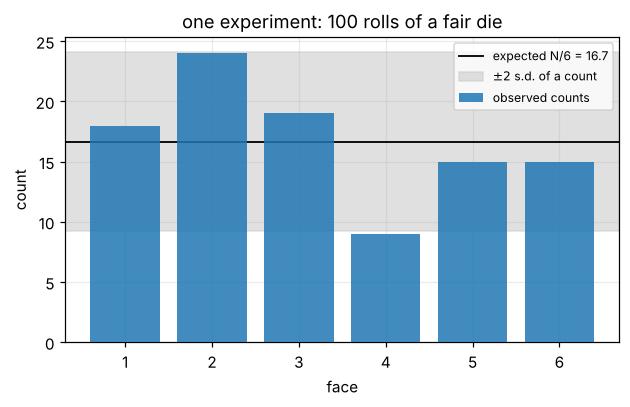

In [ ]:
# ---- ONE experiment: roll the die N = 100 times ----
rolls = rng.integers(1, 7, size=N)          # ANNOT: integers(1, 7) draws from {1,...,6}: the upper end is excluded
counts = np.bincount(rolls, minlength=7)[1:]  # ANNOT: how many 1s, 2s, ..., 6s

xbar = rolls.mean()
s0 = rolls.std(ddof=0)                      # ANNOT: ddof=0: divide by N     (the "plug-in" estimate of sigma)
s1 = rolls.std(ddof=1)                      # ANNOT: ddof=1: divide by N - 1 (the unbiased estimate of the VARIANCE)
print("counts of 1..6      :", counts, " (sum =", counts.sum(), ")")
print(f"sample mean         : {xbar:.3f}      (true mean {mu_true})")
print(f"sample sigma, ddof=0: {s0:.3f}   ddof=1: {s1:.3f}   (true sigma {sigma_true:.3f})")

expected = N / 6
sd_count = np.sqrt(N * (1 / 6) * (5 / 6))   # ANNOT: each count is Binomial(N, 1/6): sd = sqrt(N p (1-p))
fig, ax = plt.subplots()
ax.bar(faces, counts, color="C0", alpha=0.85, label="observed counts", zorder=3)
ax.axhline(expected, color="k", lw=1.2, label=f"expected N/6 = {expected:.1f}")
ax.axhspan(expected - 2 * sd_count, expected + 2 * sd_count, color="0.8", alpha=0.6, label=r"$\pm 2$ s.d. of a count", zorder=1)
ax.set_xlabel("face"); ax.set_ylabel("count"); ax.set_title("one experiment: 100 rolls of a fair die"); ax.legend(fontsize=8)
plt.show()

#### Output and figure discussion

```
counts of 1..6      : [18 24 19  9 15 15]  (sum = 100 )
sample mean         : 3.240      (true mean 3.5)
sample sigma, ddof=0: 1.715   ddof=1: 1.724   (true sigma 1.708)
```

* **The bars are not flat, and that is normal.** The counts range from 9 to 24 around the expected 16.7. Two bars sit at the edge of the grey band (face 2 at $+1.97$ and face 4 at $-2.06$ standard deviations). With six counts, one of them landing about two standard deviations out happens in roughly a quarter of experiments, so this is not evidence of a loaded die.
* **The sample mean is $3.240$, not $3.5$.** It is $0.26$ below the truth, which is $1.5$ standard errors ($0.26/0.171$). *This single experiment happened to land low.* You will see the same "luck of the draw" again in Section 7: the bootstrap is centred on this $3.24$-type number, not on the truth.
* **The sample standard deviation is close to $\sigma$**: $1.715$ ($\text{ddof}=0$) and $1.724$ ($\text{ddof}=1$) against $1.708$. The sample standard deviation is a good estimate of $\sigma$ even from 100 rolls; what is uncertain is the sample *mean*, and that is the subject of the next sections.

## 3. The sampling distribution of the mean

#### Concept

Now repeat the whole experiment $M=10{,}000$ times and keep each experiment's *mean*. The histogram of those $10{,}000$ numbers is the **sampling distribution of the mean**: the answer to "what would I have got if I had run it again?". Theory (Section "big idea") makes two predictions:

* it is centred on $\mu=3.5$ (the sample mean is an *unbiased* estimator), and
* its standard deviation is $\epsilon=\sigma/\sqrt N=0.1708$, and its shape is a Gaussian.

> **Predict.** (1) What mean and standard deviation do you expect for the 10,000 numbers? (2) What fraction should lie within one, two and three standard errors of $3.5$? (Use the Gaussian values $68\%$, $95\%$, $99.7\%$.)

#### Annotation

* `rng.integers(1, 7, size=(M, N))` makes a $10{,}000\times100$ matrix: each *row* is one experiment of 100 rolls. `.mean(axis=1)` averages along each row, giving $M$ means at once (no Python loop, which is why this takes a fraction of a second).
* The histogram is drawn with `density=True` so its area is 1 and it can be compared with the Gaussian probability density. The bin edges are placed at $x.xx5$ with width $0.02$: a mean of 100 integers can only take values that are multiples of $0.01$, and bins with edges on that grid would alternately hold one or two possible values, producing spurious spikes.

mean of the 10000 means : 3.4989     (theory 3.5)
std  of the 10000 means : 0.1717     (theory sigma/sqrt(N) = 0.1708)
fraction within 1 standard errors: 0.6941     (Gaussian: 0.6827)
fraction within 2 standard errors: 0.9547     (Gaussian: 0.9545)
fraction within 3 standard errors: 0.9979     (Gaussian: 0.9973)


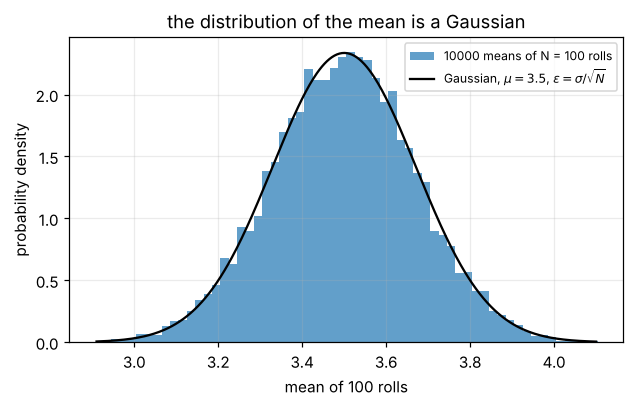

In [ ]:
# ---- repeat the experiment M = 10,000 times and keep each experiment's mean ----
# ANNOT: one matrix with M rows (experiments) and N columns (rolls); the mean along axis=1 gives one mean per experiment.
means = rng.integers(1, 7, size=(M, N)).mean(axis=1)

se_theory = sigma_true / np.sqrt(N)
print(f"mean of the {M} means : {means.mean():.4f}     (theory {mu_true})")
print(f"std  of the {M} means : {means.std():.4f}     (theory sigma/sqrt(N) = {se_theory:.4f})")
for k in (1, 2, 3):
    frac = np.mean(np.abs(means - mu_true) < k * se_theory)
    print(f"fraction within {k} standard errors: {frac:.4f}     (Gaussian: {stats.norm.cdf(k) - stats.norm.cdf(-k):.4f})")

fig, ax = plt.subplots()
# ANNOT: a mean of 100 integers is a multiple of 0.01, so bins 0.02 wide with edges at x.xx5 each hold exactly two possible values (no aliasing)
edges = np.arange(means.min() - 0.005, means.max() + 0.015, 0.02)
ax.hist(means, bins=edges, density=True, color="C0", alpha=0.7, label=f"{M} means of N = {N} rolls")
xs = np.linspace(means.min(), means.max(), 400)
ax.plot(xs, stats.norm.pdf(xs, mu_true, se_theory), "k", lw=1.5, label=r"Gaussian, $\mu=3.5$, $\epsilon=\sigma/\sqrt{N}$")
ax.set_xlabel("mean of 100 rolls"); ax.set_ylabel("probability density"); ax.legend(fontsize=8)
ax.set_title("the distribution of the mean is a Gaussian")
plt.show()

#### Output and figure discussion

```
mean of the 10000 means : 3.4989     (theory 3.5)
std  of the 10000 means : 0.1717     (theory sigma/sqrt(N) = 0.1708)
fraction within 1 standard errors: 0.6941     (Gaussian: 0.6827)
fraction within 2 standard errors: 0.9547     (Gaussian: 0.9545)
fraction within 3 standard errors: 0.9979     (Gaussian: 0.9973)
```

* **The mean of the means is $3.4989$**, indistinguishable from $3.5$. **The standard deviation of the means is $0.1717$**, against the predicted $0.1708$: a difference of $0.0009$, about $0.5\%$, which is the expected random error of a standard deviation estimated from $10{,}000$ numbers ($\approx 1/\sqrt{2M}=0.7\%$). A fair die, $N=100$: the numbers $3.5$ and $0.17$ of the original exercise are confirmed.
* **The shape is a Gaussian.** The histogram follows the black curve everywhere, even though the *individual* rolls are flat (Section 2) and take only six values. The tail fractions at two and three standard errors ($0.9547$, $0.9979$) match the Gaussian values to the digits that can be resolved.
* **The fraction within one standard error is $0.694$, not $0.683$, and the reason is instructive: the mean of 100 integers can only take values on a grid of spacing $0.01$.** One standard error is $0.1708$; the grid points inside it are $|{\bar x}-3.5|\le0.17$, and the next one is at $0.18$. A discrete distribution assigns to each grid point the probability of the whole cell around it (here $\pm0.005$), so the effective cut-off is the midpoint $0.175$, not $0.1708$. The Gaussian probability of $|Z|<0.175/0.1708=1.025$ is $0.6945$, matching the observed $0.6941$. The same correction gives $0.9566$ and $0.9974$ for two and three standard errors, against the observed $0.9547$ and $0.9979$. (I first suspected the die's flat-topped shape, but its kurtosis correction is only $-0.0005$, far too small.) Lesson: when comparing a discrete variable with a Gaussian, put the cut-off at the *midpoint* between grid points (a "continuity correction").
* **Why this matters.** The histogram is built from $10{,}000$ separate experiments, i.e. $10^6$ rolls. In a real measurement you get **one** experiment, so you will never see this histogram. Sections 7 to 9 are about getting its width anyway.

## 4. How fast does the error shrink? The $1/\sqrt N$ law

#### Concept

$\epsilon=\sigma/\sqrt N$ says that to halve the error you need **four times** as many samples, and to gain one decimal digit you need a hundred times as many. This is the most important practical consequence of the CLT: averaging works, but with sharply diminishing returns. On a log-log plot a power law $y=cN^{a}$ is a straight line of slope $a$, so the prediction is a line of slope $-1/2$.

> **Predict.** How many rolls would you need to get the standard error down to $0.05$? (Use $\epsilon=\sigma/\sqrt N$.)

#### Annotation

For each $N$ in a list from 1 to 1000 the cell runs `reps = 4000` experiments, takes the standard deviation of the 4000 means, and compares it with $\sigma/\sqrt N$. `np.polyfit(np.log(Ns), np.log(se_obs), 1)` fits a straight line to the logarithms; its slope is the exponent.

     N  observed s.d. of the mean   theory sigma/sqrt(N)
     1                     1.7041                 1.7078
     2                     1.2270                 1.2076
     5                     0.7767                 0.7638
    10                     0.5399                 0.5401
    20                     0.3798                 0.3819
    50                     0.2415                 0.2415
   100                     0.1706                 0.1708
   200                     0.1214                 0.1208
   500                     0.0751                 0.0764
  1000                     0.0536                 0.0540

fitted log-log slope = -0.503   (theory: -0.5)


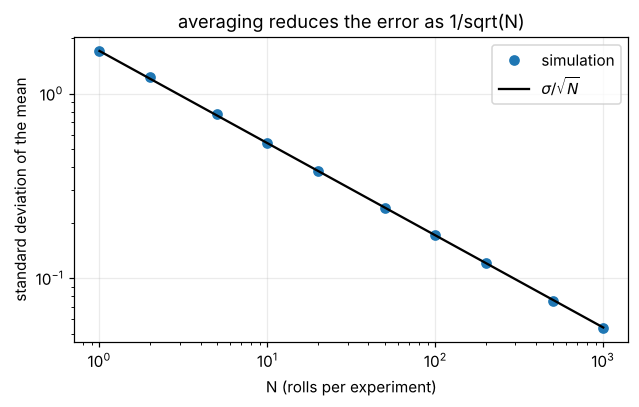

In [ ]:
# ---- how does the spread of the mean shrink with N? ----
Ns = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
reps = 4000
se_obs = []
for n in Ns:
    m = rng.integers(1, 7, size=(reps, n)).mean(axis=1)
    se_obs.append(m.std())
se_obs = np.array(se_obs)

print(f"{'N':>6} {'observed s.d. of the mean':>26} {'theory sigma/sqrt(N)':>22}")
for n, o in zip(Ns, se_obs):
    print(f"{n:6d} {o:26.4f} {sigma_true / np.sqrt(n):22.4f}")
slope, intercept = np.polyfit(np.log(Ns), np.log(se_obs), 1)   # ANNOT: a power law  y = c N^slope  is a straight line in log-log
print(f"\nfitted log-log slope = {slope:.3f}   (theory: -0.5)")

fig, ax = plt.subplots()
ax.loglog(Ns, se_obs, "o", label="simulation")
ax.loglog(Ns, sigma_true / np.sqrt(Ns), "k-", label=r"$\sigma/\sqrt{N}$")
ax.set_xlabel("N (rolls per experiment)"); ax.set_ylabel("standard deviation of the mean"); ax.legend()
ax.set_title("averaging reduces the error as 1/sqrt(N)")
plt.show()

#### Output and figure discussion

```
     N  observed s.d. of the mean   theory sigma/sqrt(N)
     1                     1.7041                 1.7078
    10                     0.5399                 0.5401
   100                     0.1706                 0.1708
  1000                     0.0536                 0.0540
fitted log-log slope = -0.503   (theory: -0.5)
```

* At $N=1$ the "mean" is a single roll, so the spread is $\sigma=1.70$; at $N=100$ it is $0.171$; at $N=1000$ it is $0.054$. The simulated and theoretical columns agree to within about $2\%$ at every $N$, which is the noise to expect from $4000$ repetitions (the standard deviation of a standard deviation estimated from 4000 numbers is about $1.1\%$); the intermediate rows are in the stored output.
* **The fitted slope is $-0.503$**, against $-0.5$: the data points sit on the line in the figure.
* **Answer to the prediction.** $N=(\sigma/0.05)^2=(1.708/0.05)^2\approx1{,}167$ rolls: more than eleven times as many as $N=100$ to reduce the error by a factor of only $3.4$. This diminishing return is why "just run longer" becomes expensive, and why knowing the standard error matters before you spend the compute.

## 5. The CLT does not need a symmetric population

#### Concept

A die is symmetric, so one might suspect that the Gaussian shape comes from symmetry. It does not. To see this, take a strongly asymmetric population: the **exponential** distribution with mean 1 (waiting times). Its standard deviation is 1, its skewness is 2 (a long right tail) and its excess kurtosis is 6. Theory says the skewness of the *mean* of $N$ draws is $2/\sqrt N$ and its excess kurtosis is $6/N$: both shrink as $N$ grows, so the distribution of the mean becomes Gaussian *gradually*.

> **Predict.** At what $N$ will the histogram of the mean look Gaussian to your eye? Does your answer depend on the skewness of the population?

#### Annotation

For each $N\in\{1,2,5,30,100\}$ the cell draws $20{,}000$ experiments from the exponential distribution (`rng.exponential(1.0, size=(Msk, n))`), averages each, and compares the histogram with the Gaussian $\mathcal N(1,\,1/\sqrt N)$. `stats.skew` and `stats.kurtosis` (excess kurtosis) measure the departure from Gaussian shape.

    N   skewness of the mean   theory 2/sqrt(N)   excess kurtosis  theory 6/N
    1                  2.037              2.000             6.264       6.000
    2                  1.424              1.414             2.980       3.000
    5                  0.936              0.894             1.361       1.200
   30                  0.380              0.365             0.249       0.200
  100                  0.190              0.200             0.072       0.060


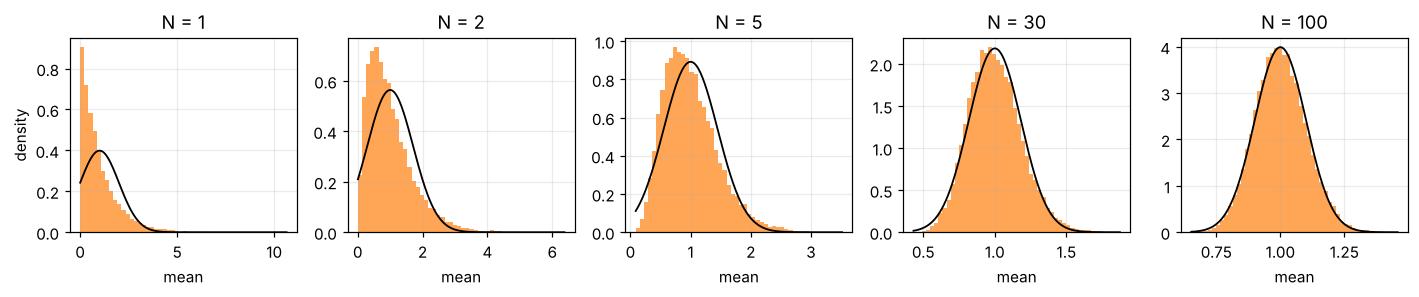

In [ ]:
# ---- the CLT for a population that is NOT symmetric: the exponential distribution ----
# ANNOT: exponential with scale 1: mean 1, sigma 1, skewness 2 (very asymmetric), excess kurtosis 6.
Ns_sk = [1, 2, 5, 30, 100]
Msk = 20_000
fig, axs = plt.subplots(1, len(Ns_sk), figsize=(13, 2.8), sharey=False)
print(f"{'N':>5} {'skewness of the mean':>22} {'theory 2/sqrt(N)':>18} {'excess kurtosis':>17} {'theory 6/N':>11}")
for ax, n in zip(axs, Ns_sk):
    m = rng.exponential(1.0, size=(Msk, n)).mean(axis=1)
    print(f"{n:5d} {stats.skew(m):22.3f} {2 / np.sqrt(n):18.3f} {stats.kurtosis(m):17.3f} {6 / n:11.3f}")
    ax.hist(m, bins=50, density=True, color="C1", alpha=0.7)
    xs = np.linspace(max(m.min(), 1e-3), m.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, 1.0, 1.0 / np.sqrt(n)), "k", lw=1.2)
    ax.set_title(f"N = {n}"); ax.set_xlabel("mean")
axs[0].set_ylabel("density")
plt.tight_layout(); plt.show()

#### Output and figure discussion

```
    N   skewness of the mean   theory 2/sqrt(N)   excess kurtosis   theory 6/N
    1                  2.037              2.000             6.264        6.000
    2                  1.424              1.414             2.980        3.000
    5                  0.936              0.894             1.361        1.200
   30                  0.380              0.365             0.249        0.200
  100                  0.190              0.200             0.072        0.060
```

* **The theory for the shape is confirmed numerically**: skewness follows $2/\sqrt N$ and excess kurtosis follows $6/N$ within the sampling noise of $20{,}000$ experiments.
* **The figure shows the convergence.** $N=1$ is the exponential itself (sharp peak at zero, long tail). $N=2$ and $N=5$ are still clearly lopsided: the histogram is above the Gaussian on the left and below it near the centre. By $N=30$ the match is already close, with a faint residual right tail (skewness $0.38$). By $N=100$ the two curves are hard to tell apart.
* **The usual rule "$N\ge30$ is enough" is a rule of thumb about skewness, not a theorem.** It works here because the exponential has a modest skewness of 2. For a population with skewness 10 you need $N\approx25$ times larger to reach the same shape quality, since the skewness of the mean falls like $1/\sqrt N$.
* **What the CLT does *not* say.** It is a statement about the distribution of the *mean*. It does not make the data Gaussian.

## 6. When the CLT does not apply: a population with no finite variance

#### Concept

Both conditions matter: *independent* draws and *finite variance*. The **Cauchy distribution** violates the second: its tails are so heavy that its variance (and even its mean) does not exist. A surprising consequence is that the average of $N$ independent Cauchy numbers is distributed *exactly like a single one*, for every $N$. Averaging gives no benefit at all.

This is not only a curiosity: heavy-tailed quantities do occur in practice (ratios of noisy numbers, rare large excursions, some energy differences), and then "mean $\pm$ standard error" is simply the wrong summary.

> **Predict.** For a fair die the running mean settles on $3.5$. What will the running mean of Cauchy numbers do? And what will the spread of the mean of $N$ Cauchy numbers do as $N$ grows 1000-fold?

#### Annotation

* The running mean after $t$ samples is `np.cumsum(x) / np.arange(1, T + 1)`, plotted against $t$ on a log axis.
* The standard deviation does not exist for Cauchy, so the spread of the mean is measured by the **interquartile range** (IQR, the distance between the 25th and 75th percentiles), which always exists. The IQR of a standard Cauchy is exactly 2.

      N   IQR of the mean (Cauchy)    IQR of the mean (die)
      1                      1.982                    3.000
     10                      2.013                    0.700
    100                      1.980                    0.240
   1000                      1.972                    0.074


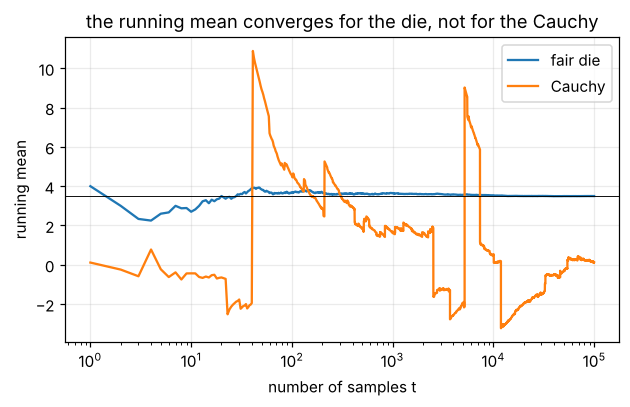

In [ ]:
# ---- when the CLT does NOT apply: a population with no finite variance (Cauchy) ----
T = 100_000
die_run = np.cumsum(rng.integers(1, 7, size=T)) / np.arange(1, T + 1)      # ANNOT: running mean after t rolls
cau_run = np.cumsum(rng.standard_cauchy(size=T)) / np.arange(1, T + 1)
fig, ax = plt.subplots()
ax.semilogx(np.arange(1, T + 1), die_run, label="fair die")
ax.semilogx(np.arange(1, T + 1), cau_run, label="Cauchy")
ax.axhline(3.5, color="k", lw=0.6); ax.set_xlabel("number of samples t"); ax.set_ylabel("running mean"); ax.legend()
ax.set_title("the running mean converges for the die, not for the Cauchy"); plt.show()

# ANNOT: spread of the mean over many experiments, measured by the interquartile range (the s.d. does not exist for Cauchy).
print(f"{'N':>7} {'IQR of the mean (Cauchy)':>26} {'IQR of the mean (die)':>24}")
for n in (1, 10, 100, 1000):
    mc = rng.standard_cauchy(size=(2000, n)).mean(axis=1)
    md = rng.integers(1, 7, size=(2000, n)).mean(axis=1)
    print(f"{n:7d} {stats.iqr(mc):26.3f} {stats.iqr(md):24.3f}")

#### Output and figure discussion

```
      N   IQR of the mean (Cauchy)    IQR of the mean (die)
      1                      1.982                    3.000
     10                      2.013                    0.700
    100                      1.980                    0.240
   1000                      1.972                    0.074
```

* **The running mean of the die (blue) settles close to 3.5** and stays there. **The running mean of the Cauchy (orange) never settles**: it makes sudden jumps of several units, even after tens of thousands of samples, each caused by one huge draw that the average then needs a very long time to dilute.
* **The IQR table says the same thing quantitatively.** For the die the spread of the mean shrinks from $3.0$ to $0.074$ over three decades of $N$ ($\approx1/\sqrt N$ again). For the Cauchy it stays at about $2.0$ whatever $N$ is, the exact IQR of a single standard Cauchy.
* **Flag.** If your data might be heavy-tailed, look at the distribution (histogram on a log scale, largest values) before reporting a mean and a standard error. The bootstrap will *not* rescue you here: it resamples the observed values and cannot invent tail behaviour that the sample does not contain.

## 7. The bootstrap: the same information from one sample

#### Concept: the practical problem

Everything so far used the **population** (we simulated $10{,}000$ new experiments). In a real study there is one sample of $N$ numbers and no way to repeat the experiment. We would like the standard error anyway.

**The bootstrap idea (Efron, 1979).** The sample is the best information we have about the population, so use it *as* the population:

1. Draw $N$ values **from your sample, with replacement** (each observed value can be picked 0, 1, 2, ... times). This is one **bootstrap resample**, the same size as the original.
2. Compute the statistic (here the mean) on the resample.
3. Repeat $B$ times (here $10{,}000$). The $B$ values form the **bootstrap distribution**.

The standard deviation of the bootstrap distribution is the **bootstrap standard error**; the 2.5th and 97.5th percentiles give a 95% **percentile interval**.

**Why it works (the plug-in principle).** Sampling from the sample means sampling from the *empirical distribution* $\hat F$, which puts probability $1/N$ on each observed value. The unknown standard error $\sigma/\sqrt N$ is a function of the unknown population; the bootstrap computes the same function of $\hat F$, whose standard deviation is $s_0$ (the `ddof=0` value). So the bootstrap standard error of a mean converges to $s_0/\sqrt N$, a quantity we can compute without ever repeating the experiment (and for statistics other than the mean, where no such formula exists, the bootstrap still works).

**Three details that trip people up.**

* **Resamples have the same size $N$ as the sample.** The standard error depends on $N$ (it is $\sigma/\sqrt N$), so resampling a different number would estimate the standard error for a different experiment.
* **"With replacement" is essential.** Resampling $N$ values *without* replacement just gives the same $N$ numbers back in a different order, with the same mean every time.
* **On average a resample contains only about $63\%$ of the distinct original values**, since the chance that a given observation is never picked is $(1-1/N)^N\approx e^{-1}=37\%$. The rest are repeats.

> **Predict.** The bootstrap distribution of the mean: (1) where will it be centred, at the true mean $3.5$ or at this sample's mean? (2) How wide will it be compared with the true sampling distribution you drew in Section 3?

#### Annotation

* `sample = rng.integers(1, 7, size=N)` is *one new* sample; from here on we pretend we do not know it came from a fair die. Its mean and `ddof=0` standard deviation are the only information used.
* `bootstrap_means` makes an $n_{\rm boot}\times N$ matrix of **indices** `rng.integers(0, len(x), size=(b - a, len(x)))` (each entry is "which observation to take", from $0$ to $N-1$, repeats allowed) and averages `x[idx]` along each row. It works in chunks of 2000 resamples to keep the memory small.
* The black curve in the figure uses the *true* $\mu$ and $\epsilon$. In real life you cannot draw it; it is shown here only so you can judge the bootstrap against the truth.

the one sample      : mean = 3.420, sigma(ddof=0) = 1.739
plug-in prediction  : s0/sqrt(N) = 0.1739
bootstrap           : mean of boot means = 3.421, standard error = 0.1745
truth (known here) : sampling distribution is centred at 3.5 with s.d. 0.1708
95% percentile interval from the bootstrap: [3.080, 3.760]   contains the true mean 3.5: True


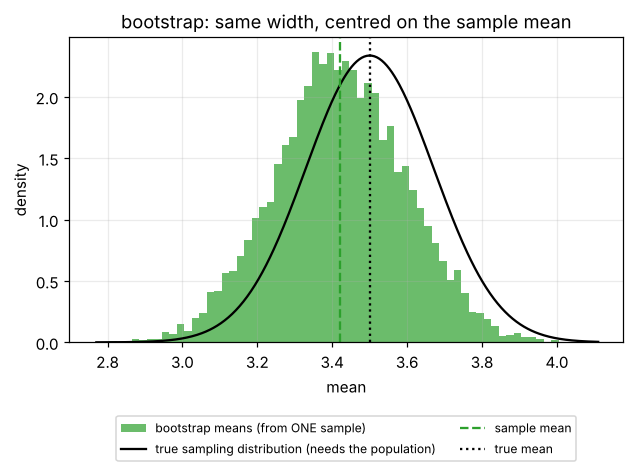

In [ ]:
# ---- the practical situation: ONE sample, unknown population ----
sample = rng.integers(1, 7, size=N)           # ANNOT: pretend we do not know this came from a fair die
xbar = sample.mean()
s0 = sample.std(ddof=0)

def bootstrap_means(x, n_boot, rng, chunk=2000):
    """Means of n_boot resamples of x, each the same size as x, drawn WITH replacement from x itself."""
    x = np.asarray(x); out = np.empty(n_boot)
    for a in range(0, n_boot, chunk):
        b = min(a + chunk, n_boot)
        idx = rng.integers(0, len(x), size=(b - a, len(x)))     # ANNOT: indices 0..N-1, with repeats allowed
        out[a:b] = x[idx].mean(axis=1)
    return out

boot = bootstrap_means(sample, B, rng)

print(f"the one sample      : mean = {xbar:.3f}, sigma(ddof=0) = {s0:.3f}")
print(f"plug-in prediction  : s0/sqrt(N) = {s0 / np.sqrt(N):.4f}")
print(f"bootstrap           : mean of boot means = {boot.mean():.3f}, standard error = {boot.std():.4f}")
print(f"truth (known here) : sampling distribution is centred at {mu_true} with s.d. {se_theory:.4f}")
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"95% percentile interval from the bootstrap: [{lo:.3f}, {hi:.3f}]   contains the true mean {mu_true}: {lo <= mu_true <= hi}")

fig, ax = plt.subplots()
edges = np.arange(boot.min() - 0.005, boot.max() + 0.015, 0.02)          # ANNOT: same alignment trick as before
ax.hist(boot, bins=edges, density=True, color="C2", alpha=0.7, label="bootstrap means (from ONE sample)")
xs = np.linspace(boot.min(), boot.max(), 400)
ax.plot(xs, stats.norm.pdf(xs, mu_true, se_theory), "k", lw=1.5, label="true sampling distribution (needs the population)")
ax.axvline(xbar, color="C2", ls="--", label="sample mean"); ax.axvline(mu_true, color="k", ls=":", label="true mean")
ax.set_xlabel("mean"); ax.set_ylabel("density"); ax.set_title("bootstrap: same width, centred on the sample mean")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)      # ANNOT: legend below the axes so it hides nothing
plt.show()

#### Output and figure discussion

```
the one sample      : mean = 3.420, sigma(ddof=0) = 1.739
plug-in prediction  : s0/sqrt(N) = 0.1739
bootstrap           : mean of boot means = 3.421, standard error = 0.1745
truth (known here) : sampling distribution is centred at 3.5 with s.d. 0.1708
95% percentile interval from the bootstrap: [3.080, 3.760]   contains the true mean 3.5: True
```

* **The width is right.** The bootstrap standard error is $0.1745$; the truth, which needs the population, is $0.1708$. The two differ by about $2\%$, the error made by estimating $\sigma$ from this particular sample ($s_0=1.739$ instead of $1.708$).
* **The bootstrap reproduces the plug-in formula.** $0.1745$ against $s_0/\sqrt N=0.1739$: with $B=10{,}000$ resamples the simulation has essentially converged to what the theory of the previous section said it must.
* **The location is the sample's, not the truth's.** The bootstrap histogram is centred at $3.421$, the mean of *this sample* ($3.420$), not at $3.5$ (the green dashed line is the bootstrap's centre; the dotted black line is the truth). **This is the single most misread feature of the bootstrap.** The bootstrap tells you how much your estimate would *fluctuate*; it cannot tell you how far this particular estimate happens to be from the truth. That error ($0.08$ here, half a standard error) is one random draw from the very distribution the bootstrap approximates.
* **The interval nevertheless covers the truth.** $[3.080,3.760]$ contains $3.5$. Why this is reliable in general, and not luck, is the subject of Section 8.

#### Annotation: what does the number of resamples $B$ buy?

A frequent misunderstanding is that more bootstrap resamples make the answer "more accurate". The next cell repeats the bootstrap standard error of the *same* sample 30 times for each of several $B$.

In [ ]:
# ---- what does the NUMBER OF RESAMPLES B buy?  (same single sample as before) ----
print(f"the plug-in value s0/sqrt(N) = {s0 / np.sqrt(N):.4f}   (the bootstrap SE can converge to this, and to nothing better)")
print(f"{'B':>8} {'mean of 30 bootstrap SEs':>26} {'spread (s.d.) over the 30':>27}")
for Bk in (10, 100, 1000, 10_000, 100_000):
    ses = [bootstrap_means(sample, Bk, rng).std() for _ in range(30)]      # ANNOT: 30 independent bootstrap runs on the SAME data
    print(f"{Bk:8d} {np.mean(ses):26.4f} {np.std(ses):27.4f}")
print(f"\nthe TRUE standard error (needs the population) is {se_theory:.4f}; it differs from s0/sqrt(N) because this one sample is not the population")

the plug-in value s0/sqrt(N) = 0.1739   (the bootstrap SE can converge to this, and to nothing better)
       B   mean of 30 bootstrap SEs   spread (s.d.) over the 30
      10                     0.1743                      0.0402
     100                     0.1747                      0.0119
    1000                     0.1732                      0.0036
   10000                     0.1740                      0.0013
  100000                     0.1739                      0.0004

the TRUE standard error (needs the population) is 0.1708; it differs from s0/sqrt(N) because this one sample is not the population


#### Output discussion

```
the plug-in value s0/sqrt(N) = 0.1739
       B   mean of 30 bootstrap SEs   spread (s.d.) over the 30
      10                     0.1743                      0.0402
     100                     0.1747                      0.0119
    1000                     0.1732                      0.0036
   10000                     0.1740                      0.0013
  100000                     0.1739                      0.0004
the TRUE standard error (needs the population) is 0.1708
```

* **$B$ controls only the simulation noise.** The average over runs is already $\approx0.174$ for $B=10$; what shrinks with $B$ is the scatter *between runs*: $0.040$ at $B=10$, $0.0036$ at $B=1000$, $0.0004$ at $B=10^5$, a decrease like $1/\sqrt{B}$ (the CLT again, now applied to the bootstrap itself).
* **$B$ cannot improve on the sample.** Even with $B=10^5$ the answer is $0.1739$, the plug-in value, not the true $0.1708$. The remaining $0.003$ difference is a property of the sample, set by $N$; no amount of resampling removes it. *The bootstrap does not create information.*
* **Practical rule.** A few thousand resamples are plenty for a standard error ($B=1000$ already gives about $2\%$ scatter); percentile intervals use the tails and want more ($B\ge$ a few thousand). Beyond that, spend the effort on a larger $N$.

## 8. Does the bootstrap interval really work? A coverage experiment

#### Concept

A **95% interval** is a promise about a *procedure*: if you repeat the whole experiment many times and build an interval each time, about 95% of the intervals should contain the true value. This is called the **coverage**. Because we know the true mean here ($3.5$), we can check the promise, something impossible with real data.

> **Predict.** Out of 1000 independent samples, how many 95% bootstrap intervals will contain $3.5$? How much does a coverage measured from 1000 trials fluctuate?

#### Annotation

Each of 1000 iterations draws a brand-new sample of $N=100$ rolls, builds a bootstrap percentile interval from $1000$ resamples, and records whether it contains $3.5$. For comparison it also builds the classical $t$-interval $\bar x\pm t_{0.975,N-1}\,s/\sqrt N$. A coverage estimated from 1000 trials has a binomial uncertainty of $\sqrt{0.95\cdot0.05/1000}=0.007$.

In [ ]:
# ---- does the 95% interval really contain the truth 95% of the time? (repeat the WHOLE procedure many times) ----
reps = 1000
hit_boot = hit_t = 0
width_boot = []
for _ in range(reps):
    x = rng.integers(1, 7, size=N)                           # a new independent sample every time
    bm = bootstrap_means(x, 1000, rng)
    lo, hi = np.percentile(bm, [2.5, 97.5])
    hit_boot += (lo <= mu_true <= hi); width_boot.append(hi - lo)
    half = stats.t.ppf(0.975, N - 1) * x.std(ddof=1) / np.sqrt(N)  # ANNOT: the textbook t-interval, for comparison
    hit_t += (x.mean() - half <= mu_true <= x.mean() + half)
se_cov = np.sqrt(0.95 * 0.05 / reps)                         # ANNOT: binomial uncertainty of a coverage estimated from 1000 trials
print(f"bootstrap percentile interval: coverage = {hit_boot / reps:.3f}   (target 0.950 +/- {se_cov:.3f}),  mean width = {np.mean(width_boot):.3f}")
print(f"classical t interval         : coverage = {hit_t / reps:.3f}")

bootstrap percentile interval: coverage = 0.941   (target 0.950 +/- 0.007),  mean width = 0.662
classical t interval         : coverage = 0.941


#### Output discussion

```
bootstrap percentile interval: coverage = 0.941   (target 0.950 +/- 0.007),  mean width = 0.662
classical t interval         : coverage = 0.941
```

* **Coverage $0.941$** against the target $0.950$: $1.3$ binomial standard errors low, i.e. consistent with $95\%$ at this precision. The promise holds for the bootstrap with $N=100$.
* **It matches the classical $t$-interval** (also $0.941$; both are computed from the same $1000$ samples, and the two intervals are nearly identical for a mean at this $N$). So for a plain mean the bootstrap adds nothing over the textbook formula; its value is for statistics where there *is* no textbook formula (Section 9).
* **Mean width $0.662$** is close to the ideal $2\times1.96\times0.1708=0.669$: the intervals are neither too wide nor too narrow.
* **Flag: it does not work for small $N$.** In a separate check (not stored in this notebook) I repeated the experiment with $N=10$ rolls and 2000 trials and found a coverage of about $0.93$, clearly below $0.95$ (uncertainty $\approx0.005$). The bootstrap resamples from only ten values, so it underestimates the spread (its $s_0$ is smaller than the unbiased $s$ by $\sqrt{9/10}$) and the Gaussian shape has not yet been reached. Try it yourself in Exercise 6.

## 9. The bootstrap beyond the mean: the median

#### Concept

For the mean we had a formula, $\sigma/\sqrt N$. For the **median** of an exponential sample the exact standard error is hard to derive, though an asymptotic formula exists: $1/(2f(m)\sqrt N)$ with $f(m)$ the population density at the median. For $\text{Exp}(1)$ the median is $\ln2=0.693$ and $f(\ln 2)=1/2$, so $\epsilon_{\rm median}=1/\sqrt N=0.100$ at $N=100$. The bootstrap needs none of this: replace "mean" by "median" in the recipe, and nothing else changes. That generality (any statistic you can compute) is the main reason the bootstrap is used.

> **Predict.** If you bootstrap the median from a *single* sample, will you get exactly the true standard error each time, or a number that varies from sample to sample?

#### Annotation

1. The "truth by brute force" is $20{,}000$ repeated experiments of 100 draws each, taking the standard deviation of their medians (possible only in a simulation).
2. The bootstrap standard error is computed from a **single** sample, repeated for 200 different samples, to see how the estimate behaves. `np.median(x[idx], axis=1)` takes the median of each resample.

true standard error of the median (20,000 repeated experiments): 0.0999   asymptotic formula: 0.1000
bootstrap SE from a single sample, over 200 samples: mean = 0.1040, spread (s.d.) = 0.0257


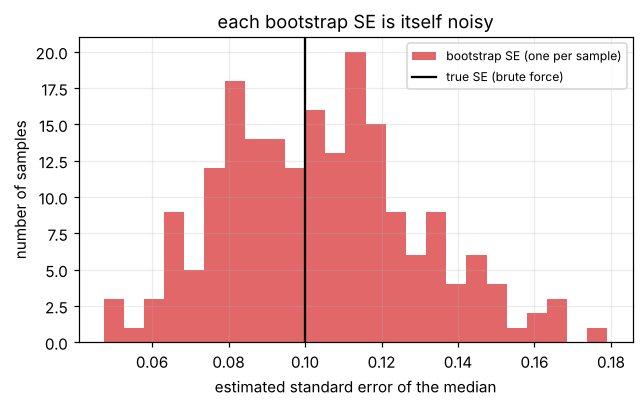

In [ ]:
# ---- the bootstrap works for statistics that have no simple formula: the MEDIAN of an exponential sample ----
# ANNOT: true median of Exp(1) is ln 2.  The asymptotic standard error of the sample median is 1/(2 f(m) sqrt(N)), f(m) = 1/2.
true_median = np.log(2)
se_median_asym = 1.0 / (2 * 0.5 * np.sqrt(N))

# "truth by brute force": repeat the experiment many times (possible only in a simulation)
meds = np.median(rng.exponential(1.0, size=(20_000, N)), axis=1)
print(f"true standard error of the median (20,000 repeated experiments): {meds.std():.4f}   asymptotic formula: {se_median_asym:.4f}")

# bootstrap standard error computed from ONE sample at a time, for 200 different samples
boot_se = []
for _ in range(200):
    x = rng.exponential(1.0, size=N)
    idx = rng.integers(0, N, size=(2000, N))
    boot_se.append(np.median(x[idx], axis=1).std())
boot_se = np.array(boot_se)
print(f"bootstrap SE from a single sample, over 200 samples: mean = {boot_se.mean():.4f}, spread (s.d.) = {boot_se.std():.4f}")

fig, ax = plt.subplots()
ax.hist(boot_se, bins=25, color="C3", alpha=0.7, label="bootstrap SE (one per sample)")
ax.axvline(meds.std(), color="k", lw=1.5, label="true SE (brute force)")
ax.set_xlabel("estimated standard error of the median"); ax.set_ylabel("number of samples"); ax.legend(fontsize=8)
ax.set_title("each bootstrap SE is itself noisy"); plt.show()

#### Output and figure discussion

```
true standard error of the median (20,000 repeated experiments): 0.0999   asymptotic formula: 0.1000
bootstrap SE from a single sample, over 200 samples: mean = 0.1040, spread (s.d.) = 0.0257
```

* **The brute-force truth agrees with the formula** ($0.0999$ vs $0.1000$).
* **The bootstrap, on average, gets it right.** Averaged over 200 samples the bootstrap SE is $0.1040$, within $4\%$ of the true $0.0999$ (the standard error of that average is $0.0257/\sqrt{200}=0.0018$, so it is about $2.3$ of those above; a small positive bias is possible and I have not tested for it).
* **But each individual bootstrap SE is itself noisy**: the spread across samples is $0.0257$, about a quarter of the value, as the histogram shows (individual values range from about $0.04$ to $0.18$). Answer to the prediction: *it varies*. A standard error estimated from one sample is itself an estimate with an error, and with $N=100$ that error is large. Quote error bars with one or two significant figures, not five.

## 10. The hidden assumption: independence (and what molecular simulations do about it)

#### Concept

Everything above assumed the $N$ values are **independent**. The data from a simulation run are not: the value at one time step is strongly correlated with the next. Consecutive samples carry largely the same information, so $N$ correlated samples are worth fewer than $N$ independent ones. For a stationary series the variance of the mean is

$$\operatorname{Var}(\bar x)\approx\frac{\sigma_x^2}{N}\,g,\qquad g=1+2\sum_{t\ge1}\rho_t\;\;(\text{the statistical inefficiency}),$$

where $\rho_t$ is the autocorrelation at lag $t$. Only $N_{\rm eff}=N/g$ samples are effectively independent. For the simplest correlated series, the **AR(1)** process $x_t=\phi\,x_{t-1}+\text{noise}$, $g=(1+\phi)/(1-\phi)$.

**What goes wrong with the bootstrap.** Resampling *single points* with replacement shuffles the time order, which destroys the correlation and treats the data as if they were independent, so the bootstrap standard error is the naive $\sigma_x/\sqrt N$: too small by $\sqrt g$. The cure is the **block bootstrap**: resample *blocks of $L$ consecutive points*, so that the dependence inside each block is kept, with $L$ larger than the correlation time (about $g$).

**Why this matters beyond a toy.** The analysis of the molecular-dynamics windows in the JSI pilot notebooks has exactly this structure: each window yields a correlated time series of $q$, the analysis thins each series by its statistical inefficiency (so that the retained samples are approximately independent), and the bootstrap is then done *within windows*. Without that step, the error bars would be too small by the factor shown here.

> **Predict.** For $\phi=0.9$, how many *effectively independent* samples are in a series of 2000 correlated points? Will the ordinary (single-point) bootstrap notice the correlation?

#### Annotation

* `ar1_series` simulates $M_t=2000$ independent series of length $N_t=2000$ (vectorised over the series, looping over time) starting from the stationary distribution; the standard deviation of their means is the **true** standard error.
* For **one** series (as in practice) it compares two bootstraps: `naive` (resample single points: `bootstrap_means`) and `block` (circular blocks of length $L=50$). The index trick `(starts[:, :, None] + np.arange(L)) % Nt` builds, for every resample, $N_t/L$ blocks of $L$ consecutive indices, wrapping around the end of the series.

In [ ]:
# ---- when the samples are NOT independent: an autocorrelated series (AR(1)) ----
phi, Nt, Mt = 0.9, 2000, 2000            # ANNOT: correlation between consecutive values, series length, number of series
var_x = 1.0 / (1 - phi**2)               # stationary variance of x_t = phi x_{t-1} + noise (noise variance 1)
g = (1 + phi) / (1 - phi)                # ANNOT: statistical inefficiency: one independent sample per g correlated ones
print(f"statistical inefficiency g = {g:.1f}  ->  effective number of independent samples N_eff = N/g = {Nt / g:.0f} out of {Nt}")

def ar1_series(n_series, n, phi, rng):
    x = np.empty((n_series, n))
    x[:, 0] = rng.normal(0, np.sqrt(1.0 / (1 - phi**2)), n_series)     # start in the stationary distribution
    eps = rng.normal(size=(n_series, n))
    for t in range(1, n):
        x[:, t] = phi * x[:, t - 1] + eps[:, t]
    return x

true_se = ar1_series(Mt, Nt, phi, rng).mean(axis=1).std()            # truth: many independent series
print(f"true s.d. of the mean over {Mt} series       : {true_se:.4f}   (theory sqrt(var*g/N) = {np.sqrt(var_x * g / Nt):.4f})")
print(f"naive formula s/sqrt(N) (assumes independence): {np.sqrt(var_x / Nt):.4f}   <-- too small by sqrt(g) = {np.sqrt(g):.2f}")

x = ar1_series(1, Nt, phi, rng)[0]                                   # ONE series, as in practice
naive = bootstrap_means(x, 4000, rng).std()                          # resample single points: destroys the correlation
L = 50                                                               # ANNOT: block length, chosen larger than the correlation time (about g)
starts = rng.integers(0, Nt, size=(4000, Nt // L))
idx = (starts[:, :, None] + np.arange(L)).reshape(4000, -1) % Nt     # ANNOT: circular blocks of L consecutive points
block = x[idx].mean(axis=1).std()
print(f"one series: naive (iid) bootstrap SE = {naive:.4f}    block bootstrap SE (L={L}) = {block:.4f}")

statistical inefficiency g = 19.0  ->  effective number of independent samples N_eff = N/g = 105 out of 2000
true s.d. of the mean over 2000 series       : 0.2199   (theory sqrt(var*g/N) = 0.2236)
naive formula s/sqrt(N) (assumes independence): 0.0513   <-- too small by sqrt(g) = 4.36
one series: naive (iid) bootstrap SE = 0.0497    block bootstrap SE (L=50) = 0.1985


#### Output discussion

```
statistical inefficiency g = 19.0  ->  effective number of independent samples N_eff = N/g = 105 out of 2000
true s.d. of the mean over 2000 series       : 0.2199   (theory sqrt(var*g/N) = 0.2236)
naive formula s/sqrt(N) (assumes independence): 0.0513   <-- too small by sqrt(g) = 4.36
one series: naive (iid) bootstrap SE = 0.0497    block bootstrap SE (L=50) = 0.1985
```

* **Only about 105 of the 2000 points are effectively independent** ($g=19$). Answer to the prediction: the series is worth about 5% of its length.
* **The truth is $0.2199$** (theory $0.2236$; the small difference is the sampling noise of 2000 series). The **naive formula**, which assumes independence, gives $0.0513$: too small by the predicted factor $\sqrt{19}=4.36$.
* **The ordinary bootstrap does not notice.** From one series its standard error is $0.0497$, essentially the naive value ($0.0513$): shuffling single points removed the correlation it was supposed to measure. An error bar from it would be about four times too small, claiming a precision the data do not have.
* **The block bootstrap recovers most of it**: $0.1985$ against the truth $0.2199$, about $10\%$ low. Part of that is the noise of a single series, part is that a finite block length cuts the longest correlations; larger $L$ reduces the bias at the cost of more variability. Block bootstraps are an approximation, not an exact fix.
* **Flag.** The two failure modes of this notebook are the same idea: the bootstrap assumes the data you resample are *independent draws from a well-behaved population*. Heavy tails (Section 6) and correlations (this section) each violate that, and the bootstrap will not warn you. Look at the autocorrelation and the distribution of your data first.

## Summary

| | |
|---|---|
| **Standard error of a mean** | $\epsilon=\sigma/\sqrt N$ (independent samples). Halving it costs four times the data. |
| **Shape** | The CLT: Gaussian for large $N$, for any population with finite variance. How large "large" is depends on the population's skewness ($2/\sqrt N$ for an exponential). |
| **When it fails** | Infinite variance (Cauchy: the average never improves); dependence between samples (effective $N$ is $N/g$). |
| **Bootstrap** | Resample the sample, with replacement, $N$ out of $N$, $B$ times. The spread of the resampled statistics estimates the standard error; percentiles give an interval. |
| **What $B$ does** | Reduces simulation noise like $1/\sqrt B$; cannot reduce the sampling error, which is set by $N$. |
| **What the bootstrap is centred on** | Your sample's statistic, not the truth. It measures *fluctuation*, not *error of this estimate*. |
| **When it is useful** | Any statistic you can compute (median, ratio, free-energy difference). For a plain mean it agrees with the classical formula. |
| **When it fails** | Heavy tails, small $N$, correlated data (use blocks or thin first), extreme-value statistics (Exercise 4). |

## Checklist before quoting a bootstrap error bar

* Are the resampled units **independent**? If the data are a time series, did you thin by the statistical inefficiency or use blocks longer than the correlation time?
* Did you look at the **distribution** of the data (heavy tails, a few huge values)?
* Is $N$ large enough that the sample represents the population (tens at least; hundreds is comfortable)?
* Is $B$ large enough that the **simulation** noise is negligible (a few thousand)? If you ran it twice, would the interval change in the second digit?
* Did you report the interval with the right number of digits (one or two significant figures)?
* Did you say what the interval is a statement about: the *variability of the estimator*, not the distance of this estimate from the truth?

## Exercises

1. For the fair die, how many rolls give a standard error of $0.05$? How many give $0.017$? What does that say about measuring something ten times more precisely?
2. In Section 7 the bootstrap distribution is centred on the sample mean and not on $3.5$. Explain why, in terms of the empirical distribution $\hat F$. What is the *mean of $\hat F$*?
3. Why does the IQR of the mean of Cauchy samples not decrease with $N$? (Hint: what is the distribution of the average of two independent standard Cauchy numbers?)
4. **Where the bootstrap fails.** Take $N=100$ values from a uniform distribution on $(0,1)$ and bootstrap the *maximum*. In what fraction of resamples is the resampled maximum exactly equal to the sample maximum? Is the bootstrap distribution a good picture of the true sampling distribution of the maximum?
5. In Section 10 use $\phi=0.5$. What is $g$? What block length would you choose? Repeat the comparison and check the three standard errors.
6. Repeat the coverage experiment of Section 8 with $N=10$ and with $N=30$. At what $N$ does the percentile interval first reach about 95%?
7. The bootstrap SE of a mean converges to $s_0/\sqrt N$ with `ddof=0`. By what factor does it differ from $s/\sqrt N$ with `ddof=1` at $N=100$? At $N=10$?
8. In a time series the statistical inefficiency is $g=40$ and the series has 80,000 points. How many independent samples is that, and what is the standard error of its mean relative to the naive $\sigma/\sqrt N$?

<details><summary>Answer sketches (click to expand)</summary>

1. $N=(1.708/0.05)^2\approx1{,}167$; for $0.017$: $N=(1.708/0.017)^2\approx10{,}100$. Ten times more precision costs a hundred times more data.
2. The resample is drawn from $\hat F$, which puts mass $1/N$ on each observed value, so its mean is exactly the sample mean $\bar x$. The bootstrap world has "true mean" $=\bar x$ and therefore fluctuates around it.
3. The mean of $N$ independent standard Cauchy variables is again standard Cauchy (for $N=2$: $(X_1+X_2)/2$ has the same distribution as $X_1$), so its spread, and hence the IQR, is the same for every $N$.
4. The chance that the sample maximum appears in a resample is $1-(1-1/N)^N\to1-e^{-1}\approx0.632$ ($0.634$ for $N=100$). So the bootstrap distribution of the maximum has a point mass of about $63\%$ on a single value, while the true sampling distribution of the maximum is continuous. The bootstrap fails because the maximum is not a smooth function of the data: it is determined by the extreme point alone.
5. $g=(1+0.5)/(1-0.5)=3$; the correlation time is short, so blocks of about $L=10$ are already several times longer than it. The naive bootstrap should then be too small only by $\sqrt3\approx1.7$, and the block bootstrap should match the truth better than in the $\phi=0.9$ case.
6. For $N=10$ a separate run gave about $0.93$; coverage rises towards $0.95$ as $N$ grows. Do not expect it to hit $0.950$ exactly at $N=30$: the binomial uncertainty of a 1000-trial estimate is $0.007$, so use more trials.
7. $\sqrt{(N-1)/N}$: $0.995$ at $N=100$, $0.949$ at $N=10$. This is one reason the bootstrap undercovers for very small $N$.
8. $N_{\rm eff}=80{,}000/40=2{,}000$ independent samples, and the standard error is larger than the naive one by $\sqrt g=6.3$.

</details>

## Notes on this edition

This notebook replaces a short exercise whose solution cells did not match its own text: the text asked for $N=100$ rolls and $10{,}000$ repetitions, while the code used $n=1000$ and $2000$, so the printed variance of the means ($0.0028$) was right for $N=1000$ but not for the stated $N=100$ ($0.029$, i.e. $\epsilon=0.17$); the quantity printed as "sigma^2" was a variance, not $\sigma$; and the exercise was titled *bootstrapping* although it demonstrated the sampling distribution of a mean (the CLT) rather than resampling from a single sample. Here the sizes match the text, both quantities are printed and labelled, and a genuine bootstrap (Sections 7 to 9), its failure modes (Sections 6 and 10) and the connection to correlated simulation data are added.